## Оглавление

- [Дневная статистика видео](#daily-statistics)
  - [Качество исходных данных](#data-quality-heading)
  - [Отбор видео по возрасту](#video-age-heading)
  - [Вывод по разделу](#daily-statistics-conclusion)
- [Динамика за 3 дня и за 7 дней, итог за 14 дней](#early-dynamics)
  - [Распределение относительного прироста (потенциальный таргет)](#relative-gain-distribution)
  - [Вывод о распределении потенциального таргета](#relative-gain-distribution-conclusion)
  - [Вывод по разделу](#early-dynamics-conclusion)
- [Характер динамики и относительный прирост](#dynamics-character)
  - [Вывод по разделу](#dynamics-character-conclusion)
- [Подписи и категории видео](#captions-categories)
  - [Переводы категорий общего топ-5](#top-category-translations)
  - [Вывод по разделу](#content-conclusion)
- [Общий вывод](#overall-conclusion)


In [1]:
import phik
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option('display.float_format', lambda x: f'{x:.3f}')

In [2]:
item_daily_feat_raw = pd.read_csv("data/item_daily_features.csv")
item_daily_feat = item_daily_feat_raw.copy()

caption_category = pd.read_csv("data/kuairec_caption_category.csv", lineterminator="\n")
caption_category[caption_category == "UNKNOWN"] = np.nan
caption_category['first_level_category_id'] = caption_category['first_level_category_id'].replace(-124, np.nan)
caption_category['second_level_category_id'] = caption_category['second_level_category_id'].replace(-124, np.nan)
caption_category['third_level_category_id'] = caption_category['third_level_category_id'].replace(-124, np.nan)

<a id="daily-statistics"></a>
## Дневная статистика видео

<a id="data-quality-heading"></a>
### Качество исходных данных
Проверяем исходную таблицу до фильтрации видео. Доли пропусков и нулей рассчитаны от всех строк. Сочетания счётчиков требуют проверки, но сами по себе не доказывают ошибку данных.

In [3]:
quality_columns = [
    "show_cnt", "play_cnt", "like_cnt", "share_cnt", "video_duration",
    "collect_cnt", "collect_user_num", "cancel_collect_cnt", "cancel_collect_user_num",
]
raw = item_daily_feat_raw
quality_summary = pd.DataFrame({
    "missing": raw[quality_columns].isna().sum(),
    "missing_pct": raw[quality_columns].isna().mean() * 100,
    "zeros": raw[quality_columns].eq(0).sum(),
    "zeros_pct": raw[quality_columns].eq(0).mean() * 100,
})
checks = {
    "Нулевые показы, положительные просмотры": raw["show_cnt"].eq(0) & raw["play_cnt"].gt(0),
    "Просмотров больше, чем показов": raw["play_cnt"].gt(raw["show_cnt"]),
    "Валидных просмотров больше всех просмотров": raw["valid_play_cnt"].gt(raw["play_cnt"]),
    "Досмотров больше всех просмотров": raw["complete_play_cnt"].gt(raw["play_cnt"]),
    "Неположительная известная длительность": raw["video_duration"].le(0),
    "Дубли video_id + date": raw.duplicated(["video_id", "date"]),
}
quality_checks = pd.DataFrame({
    "rows": {name: mask.sum() for name, mask in checks.items()},
    "rows_pct": {name: mask.mean() * 100 for name, mask in checks.items()},
})
display(quality_summary.round(2), quality_checks.round(3))

,missing,missing_pct,zeros,zeros_pct
show_cnt,0,0.000,842,0.250
play_cnt,0,0.000,23091,6.730
like_cnt,0,0.000,108335,31.550
share_cnt,0,0.000,218774,63.720
video_duration,10598,3.090,0,0.000
collect_cnt,69683,20.300,190818,55.580
collect_user_num,69683,20.300,190818,55.580
cancel_collect_cnt,69683,20.300,212996,62.040
cancel_collect_user_num,69683,20.300,212996,62.040


,rows,rows_pct
"Нулевые показы, положительные просмотры",842,0.245
"Просмотров больше, чем показов",72171,21.020
Валидных просмотров больше всех просмотров,0,0.000
Досмотров больше всех просмотров,0,0.000
Неположительная известная длительность,0,0.000
Дубли video_id + date,0,0.000


<a id="video-age-heading"></a>
### Отбор видео по возрасту

Для анализа ранней динамики оставляем только видео, у которых первая запись совпадает с датой публикации. Рабочие таблицы фильтруются по `eligible_video_ids`. Видео с поздним началом истории не используем ни в признаках, ни в таргетах.

In [4]:
video_start = item_daily_feat_raw.assign(
    first_date=pd.to_datetime(item_daily_feat_raw["date"], format="%Y%m%d"),
    upload_date=pd.to_datetime(item_daily_feat_raw["upload_dt"]),
).groupby("video_id").agg(first_date=("first_date", "min"), upload_date=("upload_date", "min"))
video_start["start_age"] = (video_start["first_date"] - video_start["upload_date"]).dt.days
eligible_video_ids = video_start.index[video_start["start_age"] == 0]
item_daily_feat = item_daily_feat_raw[item_daily_feat_raw["video_id"].isin(eligible_video_ids)].copy()
caption_category = caption_category[caption_category["video_id"].isin(eligible_video_ids)].copy()
print(f"Исключено видео: {len(video_start) - len(eligible_video_ids)}; осталось: {len(eligible_video_ids)}")
ratio_exclusion = item_daily_feat["show_cnt"].eq(0)
print(f"Из расчёта отношения исключены {ratio_exclusion.sum()} строк ({ratio_exclusion.mean():.3%}), но они сохранены для динамики и таргетов.")

Исключено видео: 1197; осталось: 9531
Из расчёта отношения исключены 668 строк (0.242%), но они сохранены для динамики и таргетов.


In [5]:
item_daily_feat_for_describe = item_daily_feat.copy().drop(columns=["video_id", "author_id", "video_width", "video_height", "music_id", "video_tag_id"])

print(len(item_daily_feat_for_describe))
item_daily_feat_for_describe.describe()

276514


,date,video_duration,show_cnt,show_user_num,play_cnt,play_user_num,play_duration,complete_play_cnt,complete_play_user_num,valid_play_cnt,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
count,276514.000,267382.000,276514.000,276514.000,276514.000,276514.000,276514.000,276514.000,276514.000,276514.000,...,276514.000,276514.000,276514.000,276514.000,276514.000,276514.000,232714.000,232714.000,232714.000,232714.000
mean,20200809.255,12546.024,108165.336,101870.462,108216.271,97647.388,2106314215.380,58624.762,55868.597,71581.810,...,52.401,46.416,0.051,0.045,58.169,56.517,23.255,23.049,1.460,1.434
std,54.101,14348.094,630477.823,603469.853,650310.428,593440.502,17765212839.406,393073.606,379916.285,460351.252,...,594.870,523.072,0.914,0.772,307.588,298.560,386.666,383.482,8.169,7.933
min,20200705.000,40.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,20200803.000,6933.000,66.000,57.000,17.000,15.000,130029.000,5.000,5.000,6.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,20200816.000,9433.000,1968.000,1676.000,1006.000,841.000,9724421.000,333.000,301.000,465.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,20200827.000,12100.000,31988.750,28935.250,27971.500,24754.000,343576549.250,12189.750,11217.000,15422.000,...,4.000,4.000,0.000,0.000,15.000,14.000,1.000,1.000,0.000,0.000
max,20200905.000,315040.000,42181538.000,38935328.000,41167951.000,37222773.000,1985889695694.000,25234431.000,24299574.000,29185183.000,...,134099.000,133802.000,198.000,176.000,34454.000,33720.000,116971.000,115859.000,2056.000,1971.000


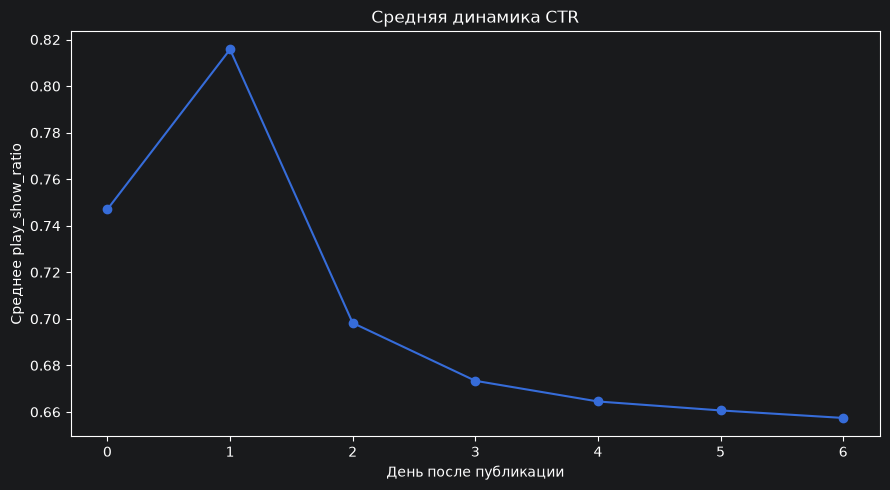

In [6]:
daily = item_daily_feat.copy()
daily["play_show_ratio"] = daily["play_cnt"] / daily["show_cnt"].where(daily["show_cnt"] > 0)

daily["date"] = pd.to_datetime(daily["date"], format="%Y%m%d")
daily["upload_dt"] = pd.to_datetime(daily["upload_dt"])

daily["age_day"] = (daily["date"] - daily["upload_dt"]).dt.days
week = daily[daily["age_day"].between(0, 6)]
full_week = week.groupby("video_id").filter(
    lambda group: group["age_day"].nunique() == 7
)
ratio_week = full_week.groupby("video_id").filter(
    lambda group: group["play_show_ratio"].notna().all()
)

curve = ratio_week.groupby("age_day")["play_show_ratio"].mean()
fig, ax = plt.subplots(figsize=(9, 5))
curve.plot(ax=ax, marker="o")
ax.set(
    title="Средняя динамика CTR",
    xlabel="День после публикации",
    ylabel="Среднее play_show_ratio",
    xticks=range(7),
)
plt.tight_layout()
plt.show()

,Просмотры за 3 дня,Просмотры за 7 дней
Медиана,50047.000,107316.000
90-й процентиль,5132238.700,7632360.100
99-й процентиль,24346652.290,31292190.020
Максимум,56011332.000,64772278.000


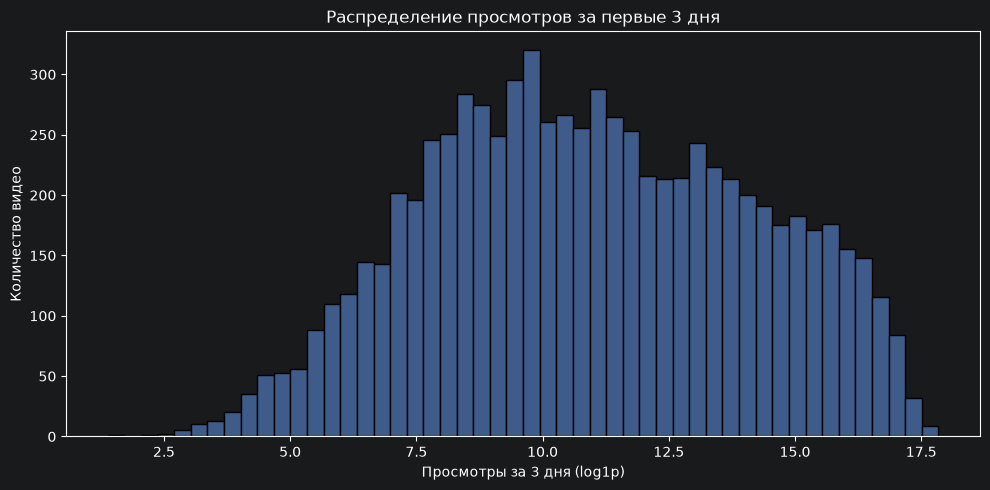

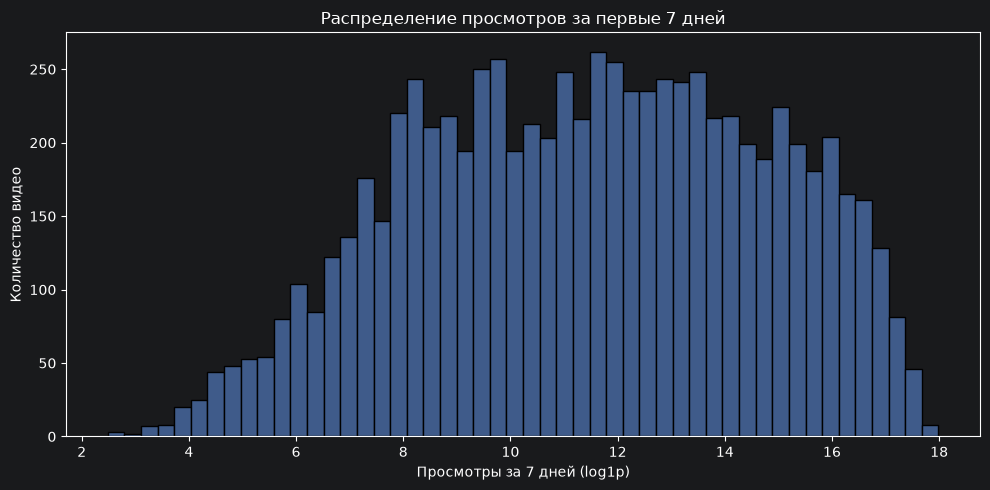

In [7]:
views_3d = full_week[full_week["age_day"] < 3].groupby("video_id")["play_cnt"].sum()
views_7d = full_week.groupby("video_id")["play_cnt"].sum()
views_quantiles = pd.DataFrame({
    "Просмотры за 3 дня": views_3d.quantile([0.5, 0.9, 0.99, 1]),
    "Просмотры за 7 дней": views_7d.quantile([0.5, 0.9, 0.99, 1]),
})
views_quantiles.index = ["Медиана", "90-й процентиль", "99-й процентиль", "Максимум"]
display(views_quantiles)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(np.log1p(views_3d), bins=50, ax=ax, color="#4C72B0")
ax.set(
    title="Распределение просмотров за первые 3 дня",
    xlabel="Просмотры за 3 дня (log1p)", ylabel="Количество видео",
)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(np.log1p(views_7d), bins=50, ax=ax, color="#4C72B0")
ax.set(
    title="Распределение просмотров за первые 7 дней",
    xlabel="Просмотры за 7 дней (log1p)",
    ylabel="Количество видео",
)
plt.tight_layout()
plt.show()

<a id="daily-statistics-conclusion"></a>
### Вывод

Распределение дневных просмотров имеет длинный хвост. Медиана составляет 1 006 просмотров, среднее достигает примерно 108 тыс. Популярные видео сильно влияют на средние значения и корреляцию Пирсона.

В исходной таблице длительность пропущена у 3,09% строк, счётчики коллекций у 20,30%. Показы, просмотры, лайки и репосты заполнены полностью.

После отбора осталось 668 строк с нулевыми показами и положительными просмотрами, или 0,242% рабочей таблицы. Эти строки сохраняем для анализа динамики, а отношение просмотров к показам рассчитываем только при положительном знаменателе. Оно может превышать 1, поэтому трактовать его как вероятность некорректно. Нулевые дни и большие значения счётчиков также сохраняем.


<a id="early-dynamics"></a>
## Динамика за 3 дня и за 7 дней, итог за 14 дней

День 0 - дата публикации видео. Оставляем только видео, у которых первая запись совпадает с публикацией и есть 14 последовательных дней без пропусков. Сравниваем показатели первых 3 и 7 дней с суммами просмотров, лайков и репостов за дни 0-13.

Первые 3 дня и первые 7 дней входят в итог: часть корреляции возникает из-за этого пересечения.

**Почему 14 дней:** это компромисс между длиной наблюдения и размером выборки. После отбора по возрасту осталось 9 531 видео; полные 14 дней есть у 6 324 (66,35%). Полные 7 дней есть у 7 720 видео (81,00%), 28 дней - у 4 891 (51,32%). Две недели позволяют сопоставить первые 3 и 7 дней с более длительным продолжением. Из прежней 14-дневной выборки исключены 1 105 видео (14,9%), наблюдение которых началось после публикации.

На графиках оставлен сильнейший по модулю признак для каждого таргета в каждом методе. Объединяем выбранные признаки, чтобы сравнивать одинаковые строки у Пирсона и Спирмена.

In [8]:
n_days = 14
observed = item_daily_feat.copy()
observed["date"] = pd.to_datetime(observed["date"], format="%Y%m%d")
observed["upload_dt"] = pd.to_datetime(observed["upload_dt"])
observed = observed.sort_values(["video_id", "date"])
assert not observed.duplicated(["video_id", "date"]).any()
observed["day"] = (
    observed["date"] - observed["upload_dt"]
).dt.days

continuous = observed[observed["day"] == observed.groupby("video_id").cumcount()]
history_lengths = continuous.groupby("video_id").size()
selected_ids = history_lengths[history_lengths >= n_days].index
window = continuous[continuous["video_id"].isin(selected_ids) & (continuous["day"] < n_days)]

video_targets = window.groupby("video_id").agg(
    views_14d=("play_cnt", "sum"),
    likes_14d=("like_cnt", "sum"),
    shares_14d=("share_cnt", "sum"),
)
dynamic_features_by_window = {}
for days in [3, 7]:
    first_days = window[window["day"] < days]
    features = first_days.set_index(["video_id", "day"])[
        ["show_cnt", "play_cnt", "like_cnt", "share_cnt"]
    ].unstack("day")
    features.columns = [f"{metric}_day_{day}" for metric, day in features.columns]
    for day in range(1, days):
        features[f"views_change_day_{day}"] = (
            features[f"play_cnt_day_{day}"] - features[f"play_cnt_day_{day - 1}"]
        )
    dynamic_features_by_window[days] = features

print(f"Окно: {n_days} дней; видео: {len(video_targets)} из {len(history_lengths)} с началом в день публикации ({len(video_targets) / len(history_lengths):.2%})")
video_targets.sample(5, random_state=42)

Окно: 14 дней; видео: 6324 из 9531 с началом в день публикации (66.35%)


,views_14d,likes_14d,shares_14d
video_id,,,
4748,13220,83,3
425,20127530,976441,2385
6247,86804,1643,63
2536,1524705,50848,738
8959,3800,13,0


<a id="relative-gain-distribution"></a>
### Распределение относительного прироста (потенциальный таргет)

Для просмотров, лайков и репостов исследуем прирост после первых 3 и 7 дней до конца 14-дневного окна:

$$
g_h = \frac{S_{14} - S_h}{S_h}, \qquad h \in \{3, 7\},\quad S_h > 0.
$$

Значение 0 означает отсутствие новых событий, 1 - прибавку, равную уже набранному. При нулевой начальной сумме прирост не определён; отдельно считаем случаи с последующей активностью и без неё. Такие видео исключаются только для соответствующего таргета и окна.

Графики показывают долю видео в фиксированных диапазонах прироста. Окна 3 и 7 дней сравниваем на одной шкале; значения выше 5 выделены в отдельную группу, поэтому хвост не обрезается. Проценты на оси относятся к доле видео, сам прирост выражен в долях от уже набранного. Например, при старте 1 000 прирост 0,5 означает ещё 500 событий к концу 14-го дня. При сравнении окон учитываем, что после трёх дней остаётся 11 дней, а после семи - 7.

In [9]:
relative_gains = {}
relative_gain_samples = {}
gain_statistics = []
gain_quantiles = []

for days in [3, 7]:
    known = window[window["day"] < days].groupby("video_id")[["play_cnt", "like_cnt", "share_cnt"]].sum()
    known.columns = video_targets.columns
    future = video_targets - known
    gains = future / known.replace(0, np.nan)
    gains.columns = ["views_gain", "likes_gain", "shares_gain"]
    relative_gains[days] = gains
    relative_gain_samples[days] = gains.notna().sum()
    for target, column in zip(gains.columns, video_targets.columns):
        values = gains[target].dropna()
        quantiles = values.quantile([0, .01, .05, .25, .5, .75, .9, .95, .99, 1])
        gain_quantiles.append({"known_days": days, "target": target, **dict(zip(
            ["min", "P1", "P5", "P25", "median", "P75", "P90", "P95", "P99", "max"], quantiles,
        ))})
        gain_statistics.append({
            "known_days": days, "target": target, "total": len(gains), "valid": len(values),
            "excluded": gains[target].isna().sum(), "excluded_pct": gains[target].isna().mean() * 100,
            "zero_start_with_future": (known[column].eq(0) & future[column].gt(0)).sum(),
            "zero_start_without_future": (known[column].eq(0) & future[column].eq(0)).sum(),
            "zero_gain": values.eq(0).sum(), "above_P99": values.gt(quantiles.loc[.99]).sum(),
        })

gain_statistics = pd.DataFrame(gain_statistics).set_index(["known_days", "target"])
gain_quantiles = pd.DataFrame(gain_quantiles).set_index(["known_days", "target"])
display(gain_statistics.round(2), gain_quantiles.round(3))

total  valid  excluded  excluded_pct  \
known_days target                                              
3          views_gain    6324   6324         0         0.000   
           likes_gain    6324   6298        26         0.410   
           shares_gain   6324   4857      1467        23.200   
7          views_gain    6324   6324         0         0.000   
           likes_gain    6324   6309        15         0.240   
           shares_gain   6324   5082      1242        19.640   

                        zero_start_with_future  zero_start_without_future  \
known_days target                                                           
3          views_gain                        0                          0   
           likes_gain                       13                         13   
           shares_gain                     334                       1133   
7          views_gain                        0                          0   
           likes_gain                        2                         13   
           shares_gain                     109                       1133   

                        zero_gain  above_P99  
known_days target                             
3          views_gain           0         64  
           likes_gain         289         63  
           shares_gain        736         49  
7          views_gain           4         64  
           likes_gain         609         64  
           shares_gain       1155         51

min    P1    P5   P25  median   P75   P90    P95  \
known_days target                                                           
3          views_gain  0.000 0.002 0.009 0.204   0.888 2.503 6.655 14.200   
           likes_gain  0.000 0.000 0.001 0.197   0.813 2.133 6.019 13.413   
           shares_gain 0.000 0.000 0.000 0.226   0.929 2.333 5.939 11.228   
7          views_gain  0.000 0.000 0.002 0.045   0.236 0.561 1.093  1.656   
           likes_gain  0.000 0.000 0.000 0.036   0.215 0.506 1.025  1.747   
           shares_gain 0.000 0.000 0.000 0.013   0.231 0.554 1.111  1.833   

                           P99       max  
known_days target                         
3          views_gain  119.781 51826.591  
           likes_gain   97.092 31543.667  
           shares_gain  51.604  1755.000  
7          views_gain    6.385 39316.483  
           likes_gain    6.222  2399.000  
           shares_gain   5.896   449.933

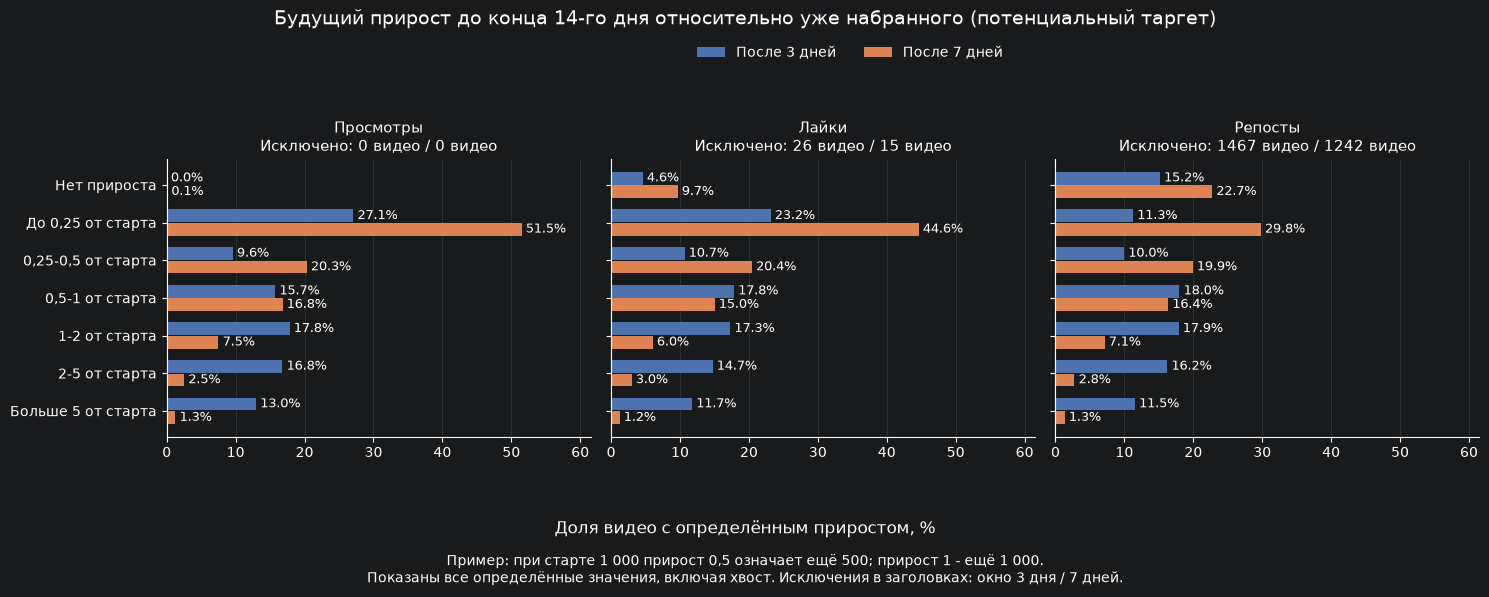

In [10]:
gain_bins = [-np.inf, 0, .25, .5, 1, 2, 5, np.inf]
gain_labels = [
    "Нет прироста", "До 0,25 от старта", "0,25-0,5 от старта",
    "0,5-1 от старта", "1-2 от старта", "2-5 от старта", "Больше 5 от старта",
]
gain_bin_shares = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=True, sharey=True)
positions = np.arange(len(gain_labels))
maximum_share = 0

for ax, (target, name) in zip(axes, [
    ("views_gain", "Просмотры"), ("likes_gain", "Лайки"), ("shares_gain", "Репосты"),
]):
    shares = pd.DataFrame(index=gain_labels)
    for days, offset, color in [(3, -0.18, "#4C72B0"), (7, 0.18, "#DD8452")]:
        values = relative_gains[days][target].dropna()
        groups = pd.cut(values, bins=gain_bins, labels=gain_labels)
        shares[days] = groups.value_counts(sort=False, normalize=True) * 100
        bars = ax.barh(positions + offset, shares[days], height=0.34, color=color, label=f"После {days} дней")
        ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    gain_bin_shares[target] = shares
    maximum_share = max(maximum_share, shares.to_numpy().max())
    excluded_3 = gain_statistics.loc[(3, target), "excluded"]
    excluded_7 = gain_statistics.loc[(7, target), "excluded"]
    ax.set_title(f"{name}\nИсключено: {excluded_3} видео / {excluded_7} видео", fontsize=11)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

axes[0].set_yticks(positions, gain_labels)
axes[0].invert_yaxis()
axes[0].set_xlim(0, maximum_share + 10)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.57, 0.94), ncol=2, frameon=False)
fig.suptitle("Будущий прирост до конца 14-го дня относительно уже набранного (потенциальный таргет)", fontsize=14)
fig.supxlabel("Доля видео с определённым приростом, %", y=0.10)
fig.text(0.5, 0.025, "Пример: при старте 1 000 прирост 0,5 означает ещё 500; прирост 1 - ещё 1 000.\nПоказаны все определённые значения, включая хвост. Исключения в заголовках: окно 3 дня / 7 дней.", ha="center", fontsize=10)
plt.tight_layout(rect=(0, 0.15, 1, 0.88))
plt.show()

<a id="relative-gain-distribution-conclusion"></a>
### Вывод о распределении потенциального таргета

После первых трёх дней у 26-28% видео дальнейшая прибавка составляет не больше четверти уже набранного. При этом у 11,5-13% она превышает набранное более чем в пять раз.

После семи дней небольшая прибавка встречается чаще. Она не превышает четверти набранного у 51,6% видео по просмотрам, 54,3% по лайкам и 52,5% по репостам. Прирост больше пятикратной суммы встречается у 1,2-1,3%. Все доли рассчитаны для видео с определённым относительным приростом.

Среди видео, уже получивших репосты за первую неделю, у 22,7% новых репостов больше не появляется. Для лайков эта доля составляет 9,7%, для просмотров 0,1%.

Относительный прирост просмотров определён у всех 6 324 видео. Из расчёта прироста лайков исключены 26 видео для трёхдневного окна и 15 для семидневного. Для репостов исключены 1 467 и 1 242 видео соответственно. Из них 334 и 109 получили репосты позже. Для таких случаев можно использовать абсолютную прибавку.

При сравнении окон нужно учитывать длину оставшегося периода. После трёх дней прогнозируем следующие 11 дней, после семи следующие 7 дней. Кроме того, за неделю видео успевает набрать больше событий, что влияет на знаменатель относительного прироста.


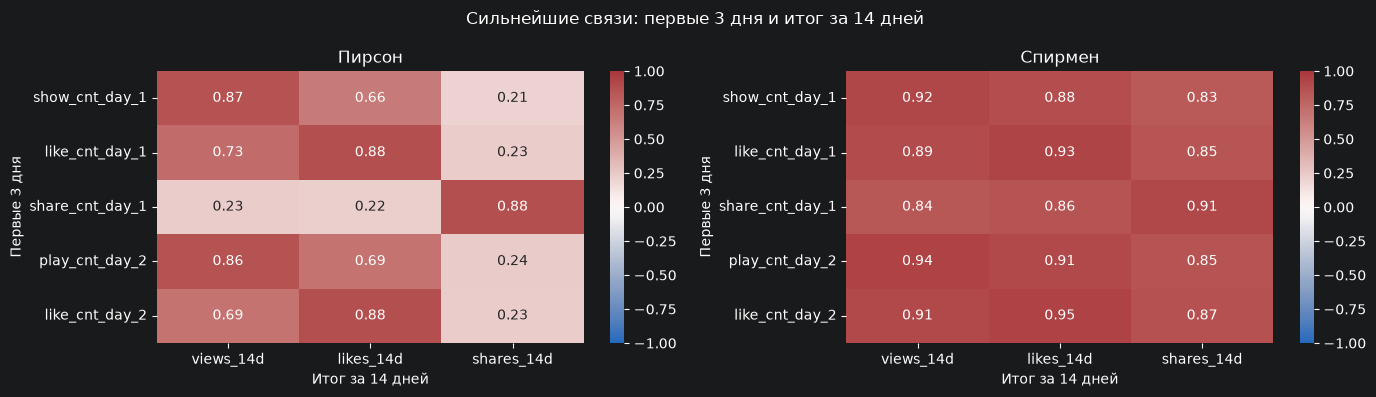

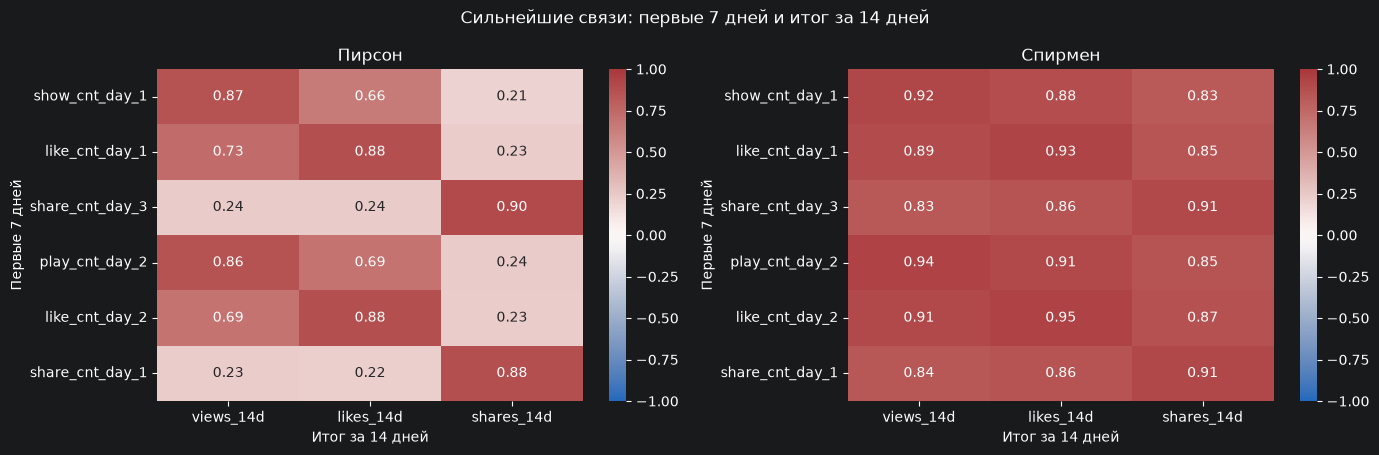

In [11]:
pearson_corr = {}
spearman_corr = {}

for days, features in dynamic_features_by_window.items():
    correlation_data = features.join(video_targets, validate="one_to_one")
    pearson_corr[days] = correlation_data.corr(method="pearson").loc[
        features.columns, video_targets.columns,
    ]
    spearman_corr[days] = correlation_data.corr(method="spearman").loc[
        features.columns, video_targets.columns,
    ]
    strongest = list(dict.fromkeys([
        *pearson_corr[days].abs().idxmax(),
        *spearman_corr[days].abs().idxmax(),
    ]))
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(strongest) * 0.6 + 1)))
    for ax, matrix, title in zip(
        axes, [pearson_corr[days], spearman_corr[days]], ["Пирсон", "Спирмен"],
    ):
        sns.heatmap(matrix.loc[strongest], annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
        ax.set(title=title, xlabel=f"Итог за {n_days} дней", ylabel=f"Первые {days} {'дня' if days == 3 else 'дней'}")
    fig.suptitle(f"Сильнейшие связи: первые {days} {'дня' if days == 3 else 'дней'} и итог за {n_days} дней")
    plt.tight_layout()
    plt.show()

<a id="early-dynamics-conclusion"></a>
### Вывод

Ранние счётчики сильно связаны с суммами за 14 дней. Максимальные коэффициенты Спирмена составляют около 0,94 для просмотров, 0,95 для лайков и 0,91 для репостов. Часть этой связи объясняется тем, что первые дни входят в итоговую сумму. Для задачи прогноза нужно отдельно проверить связь ранней статистики с последующим приростом.


<a id="dynamics-character"></a>
## Характер динамики и относительный прирост

Кластеризуем форму просмотров за первые 3 дня и за первые 7 дней, без масштаба. KMeans распределяет все видео по группам. Число кластеров выбираем по silhouette среди 2-8, без использования будущих показателей.

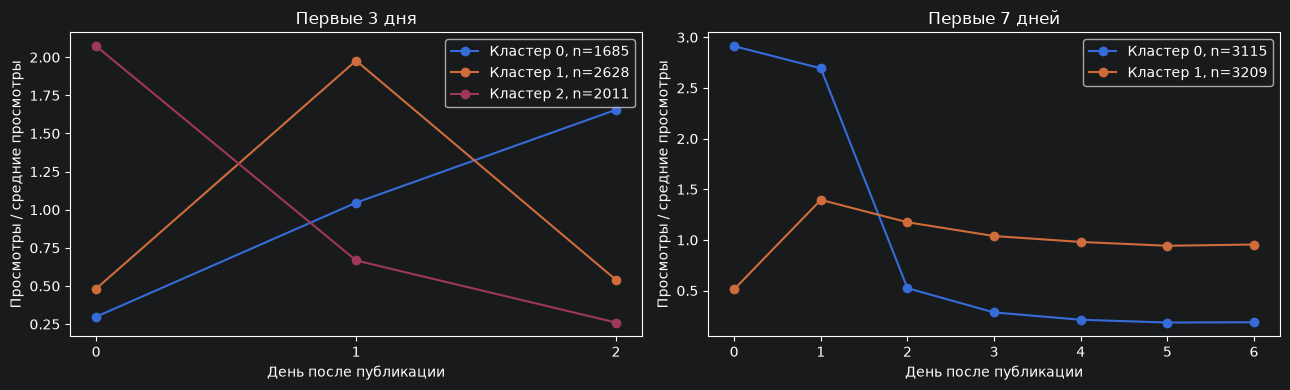

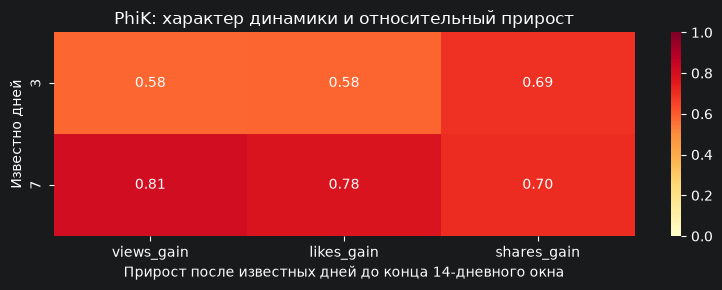

In [12]:
dynamics_clusters = {}
dynamics_cluster_summary = {}
cluster_phik = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, days in zip(axes, [3, 7]):
    values = window[window["day"] < days].pivot(
        index="video_id", columns="day", values="play_cnt",
    )
    shape = values.div(values.mean(axis=1).replace(0, np.nan), axis=0).fillna(0)
    scaled_shape = StandardScaler().fit_transform(shape)
    candidates = {}
    for k in range(2, 9):
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled_shape)
        quality = silhouette_score(scaled_shape, kmeans.labels_, sample_size=1000, random_state=42)
        candidates[k] = (quality, kmeans)
    best_k = max(candidates, key=lambda k: candidates[k][0])
    labels = pd.Series(candidates[best_k][1].labels_, index=shape.index, name="cluster")
    dynamics_clusters[days] = labels

    gain = relative_gains[days]
    binned_gain = gain.apply(lambda values: pd.qcut(values, q=10, duplicates="drop"))

    summary = gain.join(labels).groupby("cluster").median()
    summary.insert(0, "videos", labels.value_counts())
    dynamics_cluster_summary[days] = summary
    for cluster, curve in shape.groupby(labels).mean().iterrows():
        ax.plot(curve.index, curve.values, marker="o", label=f"Кластер {cluster}, n={summary.loc[cluster, 'videos']}")
    ax.set(title=f"Первые {days} {'дня' if days == 3 else 'дней'}", xlabel="День после публикации", ylabel="Просмотры / средние просмотры", xticks=range(days))
    ax.legend()

    row = {"known_days": days}
    for target in gain.columns:
        pair = pd.concat([labels, binned_gain[target]], axis=1).dropna()
        row[target] = pair.phik_matrix(interval_cols=[], njobs=1).loc["cluster", target]
    cluster_phik.append(row)

plt.tight_layout()
plt.show()
cluster_phik = pd.DataFrame(cluster_phik).set_index("known_days")
fig, ax = plt.subplots(figsize=(8, 3))
sns.heatmap(cluster_phik, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=ax)
ax.set(title="PhiK: характер динамики и относительный прирост", xlabel="Прирост после известных дней до конца 14-дневного окна", ylabel="Известно дней")
plt.tight_layout()
plt.show()

<a id="dynamics-character-conclusion"></a>
### Вывод

Форма ранней динамики связана с последующим относительным приростом. По первым трём дням PhiK составляет 0,57 для просмотров, 0,58 для лайков и 0,69 для репостов. По первым семи дням значения равны 0,81, 0,78 и 0,70. Медианный прирост просмотров в двух семидневных кластерах составляет примерно 6% и 49% от уже набранного.

В модели стоит проверить признаки формы вместе с количеством событий за первые дни. При интерпретации связи нужно учитывать, что нормировка траектории и относительный прирост используют одну раннюю историю. Кроме того, для трёх дней получено три кластера, а для семи два. Пользу этих признаков для прогноза проверим на отложенных данных.


<a id="captions-categories"></a>
## Подписи и категории видео

Проверяем связь категорий с популярностью и характером динамики. Для каждого уровня используем видео с заполненной категорией этого уровня.


In [13]:
category_columns = [
    "first_level_category_id", "second_level_category_id", "third_level_category_id",
]
category_summary = pd.DataFrame({
    "filled": caption_category[category_columns].notna().sum(),
    "filled_pct": caption_category[category_columns].notna().mean() * 100,
    "unique_categories": caption_category[category_columns].nunique(),
})
category_summary.round(2)


,filled,filled_pct,unique_categories
first_level_category_id,9496,99.630,38
second_level_category_id,6345,66.570,137
third_level_category_id,3462,36.320,214


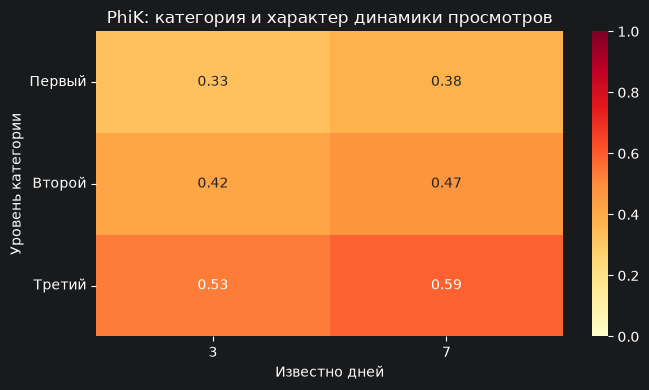

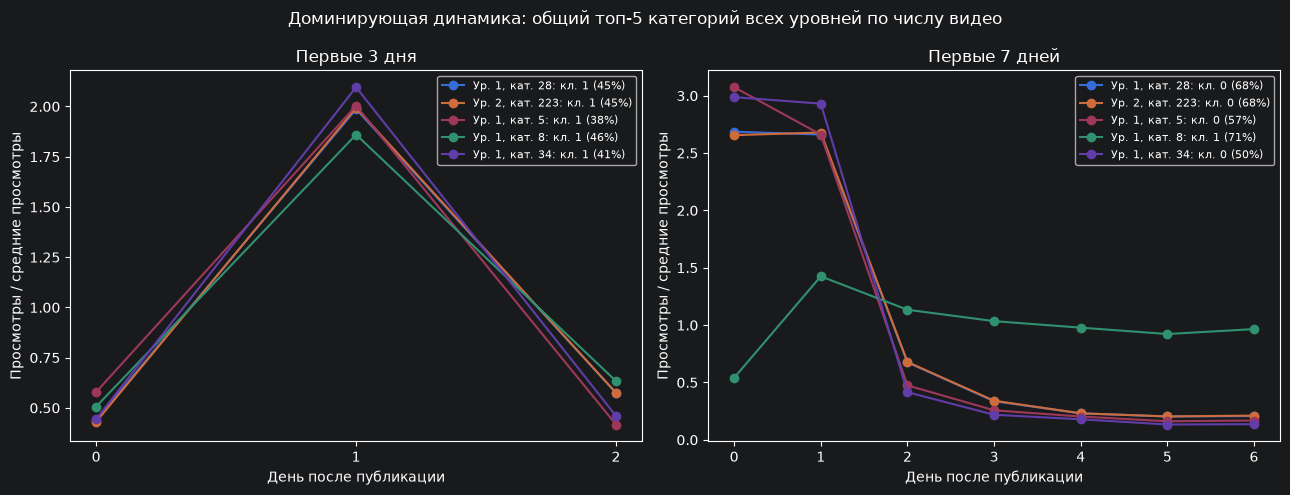

In [14]:
categories = caption_category.set_index("video_id")[category_columns].replace(-124, np.nan)
category_dynamics_phik = pd.DataFrame(index=category_columns, columns=[3, 7], dtype=float)
category_dynamics_samples = category_dynamics_phik.copy()

for days, labels in dynamics_clusters.items():
    combined = categories.join(labels, how="inner", validate="one_to_one")
    for category in category_columns:
        pair = combined[[category, "cluster"]].dropna()
        category_dynamics_samples.loc[category, days] = len(pair)
        category_dynamics_phik.loc[category, days] = pair.phik_matrix(
            interval_cols=[], njobs=1,
        ).loc[category, "cluster"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(category_dynamics_phik, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="YlOrRd", ax=ax)
ax.set(
    title="PhiK: категория и характер динамики просмотров",
    xlabel="Известно дней", ylabel="Уровень категории",
    yticks=np.arange(3) + 0.5, yticklabels=["Первый", "Второй", "Третий"],
)
plt.tight_layout()
plt.show()

category_info = caption_category.set_index("video_id")
category_ranking = pd.concat([
    categories.loc[video_targets.index, category].value_counts().rename_axis("category_id")
    .reset_index(name="videos").assign(level=level, column=category)
    for level, category in enumerate(category_columns, start=1)
], ignore_index=True).nlargest(5, "videos")

top_category_dynamics = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (days, labels) in zip(axes, dynamics_clusters.items()):
    values = window[window["day"] < days].pivot(index="video_id", columns="day", values="play_cnt")
    shape = values.div(values.mean(axis=1).replace(0, np.nan), axis=0).fillna(0)
    combined = categories.join(labels, how="inner")
    for _, category in category_ranking.iterrows():
        members = combined[combined[category["column"]] == category["category_id"]]
        cluster_counts = members["cluster"].value_counts()
        dominant = cluster_counts.idxmax()
        share = cluster_counts.loc[dominant] / len(members)
        name_column = category["column"].replace("_id", "_name")
        category_name = category_info.loc[members.index, name_column].iloc[0]
        top_category_dynamics.append({
            "level": category["level"], "category_id": int(category["category_id"]),
            "category_name": category_name, "videos": len(members), "known_days": days,
            "dominant_cluster": dominant, "cluster_videos": cluster_counts.loc[dominant],
            "cluster_share": share,
        })
        curve = shape.loc[members.index[members["cluster"] == dominant]].mean()
        ax.plot(curve.index, curve.values, marker="o", label=f"Ур. {category['level']}, кат. {int(category['category_id'])}: кл. {dominant} ({share:.0%})")
    ax.set(
        title=f"Первые {days} {'дня' if days == 3 else 'дней'}",
        xlabel="День после публикации", ylabel="Просмотры / средние просмотры", xticks=range(days),
    )
    ax.legend(fontsize=8)
fig.suptitle("Доминирующая динамика: общий топ-5 категорий всех уровней по числу видео")
plt.tight_layout()
plt.show()

<a id="top-category-translations"></a>
### Переводы категорий общего топ-5

| Уровень | ID | Категория | Перевод |
|---:|---:|---|---|
| 1 | 28 | 民生资讯 | Новости повседневной и общественной жизни |
| 2 | 223 | 社会事件 | Общественные события и происшествия |
| 1 | 5 | 时尚 | Мода и стиль |
| 1 | 8 | 颜值 | Внешность и привлекательность |
| 1 | 34 | 其他 | Прочее |

Названия переведены приблизительно с учётом тематики категорий.

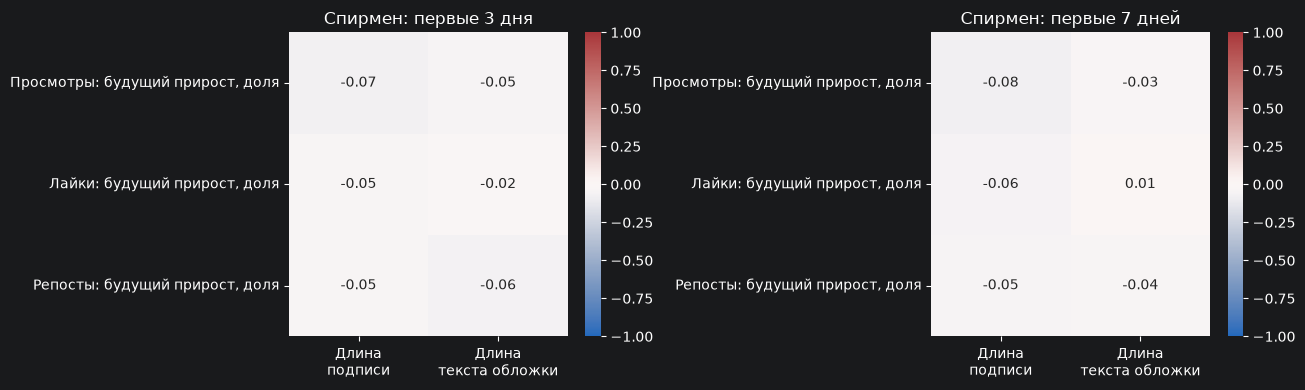

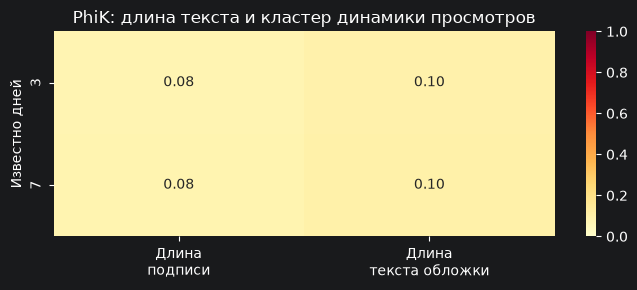

In [15]:
text_features = caption_category.set_index("video_id")[["caption", "manual_cover_text"]].copy()
for column in text_features:
    text = text_features[column].astype("string").replace("UNKNOWN", pd.NA).str.strip()
    text_features[column] = text.replace("", pd.NA).str.len().astype(float)
text_features.columns = ["Длина\nподписи", "Длина\nтекста обложки"]
text_features = text_features.reindex(video_targets.index)

text_dynamics_corr = {}
text_cluster_phik = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, days in zip(axes, [3, 7]):
    dynamics = relative_gains[days].rename(columns={
        "views_gain": "Просмотры: будущий прирост, доля",
        "likes_gain": "Лайки: будущий прирост, доля",
        "shares_gain": "Репосты: будущий прирост, доля",
    })
    combined = text_features.join(dynamics, validate="one_to_one")
    matrix = combined.corr(method="spearman").loc[text_features.columns, dynamics.columns]
    text_dynamics_corr[days] = matrix
    sns.heatmap(matrix.T, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
    ax.set(title=f"Спирмен: первые {days} {'дня' if days == 3 else 'дней'}", xlabel="", ylabel="")

    row = {}
    for primitive in text_features:
        pair = pd.concat([text_features[primitive], dynamics_clusters[days]], axis=1).dropna()
        pair[primitive] = pd.qcut(pair[primitive], q=10, duplicates="drop")
        row[primitive] = pair.phik_matrix(interval_cols=[], njobs=1).loc[primitive, "cluster"]
    text_cluster_phik[days] = row

plt.tight_layout()
plt.show()
text_cluster_phik = pd.DataFrame(text_cluster_phik).T
fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(text_cluster_phik, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=ax)
ax.set(title="PhiK: длина текста и кластер динамики просмотров", xlabel="", ylabel="Известно дней")
plt.tight_layout()
plt.show()

<a id="content-conclusion"></a>
### Вывод

Категории связаны с формой динамики просмотров. PhiK составляет от 0,33 до 0,38 для первого уровня и от 0,53 до 0,59 для третьего. Для сравнения уровней нужно учитывать разное число категорий и объём данных. На первом уровне доступны 6 312 видео, на втором 4 484, на третьем 2 414.

Длина подписи и текста обложки слабо связана с относительным приростом. Модуль Спирмена не превышает 0,10, а PhiK с кластером динамики составляет примерно от 0,08 до 0,10. Подписи доступны у 5 716 видео, текст обложки у 2 589. Анализ содержания текста остаётся отдельной задачей.


<a id="overall-conclusion"></a>
## Общий вывод

По результатам EDA выбираем задачу прогноза дополнительных просмотров, лайков и репостов после первых 3 или 7 дней до конца второй недели.

Абсолютную и относительную прибавку рассчитываем по формулам

$$
\Delta_h=S_{14}-S_h,\qquad g_h=\frac{\Delta_h}{S_h}.
$$

Здесь $S_h$ обозначает сумму за первые $h\in\{3,7\}$ дней, а $S_{14}$ сумму за 14 дней. Относительный прирост определён при $S_h>0$.

Для модели используем ранние счётчики, их дневные значения и признаки формы динамики. Категории можно проверить как дополнительные признаки. Связь длины текстов с приростом оказалась слабой.

Результаты получены на 6 324 видео с полной двухнедельной историей от публикации. Дальше нужно проверить, насколько ранняя статистика помогает прогнозировать будущий прирост на отложенных данных.
